# Ecuador Infant Malnutrition Competition (IISEM2026 MCD)

**Objetivo:** maximizar la *accuracy* en el leaderboard privado (≈90 % de `X_test`) con **un único envío**.

**Principio de decisión:** toda elección (preprocesamiento, modelo, hiperparámetros, umbral) se toma exclusivamente con validación cruzada sobre `X_train` (70 000 filas, EE ≈ 0.0011). El leaderboard público (≈3 000 filas, EE ≈ 0.0055) no se usa para decidir.

**Estructura esperada del repositorio**
```
mcd_infant_malnutrition_competition/
├── datasets/
│   ├── X_train_Kaggle.csv
│   ├── y_train_Kaggle.csv
│   ├── X_test_Kaggle.csv
│   └── sample_submission_malnutrition.csv
├── submissions/            ← se crea automáticamente
└── Kaggle - Ecuador Infant Malnutrition Competition.ipynb
```

## 0. Instalación de dependencias

In [1]:
import importlib.util, subprocess, sys

# módulo importable -> nombre del paquete en pip
REQUIRED = {
    "numpy": "numpy",
    "pandas": "pandas",
    "scipy": "scipy",
    "sklearn": "scikit-learn>=1.4",   # >=1.4 por categorical_features="from_dtype"
    "matplotlib": "matplotlib",
    "packaging": "packaging",
}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Instalando:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
else:
    print("Todas las dependencias están instaladas.")

# Verificación de versión mínima de scikit-learn
import sklearn
from packaging.version import Version
if Version(sklearn.__version__) < Version("1.4"):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "--upgrade", "scikit-learn>=1.4"])
    print("scikit-learn actualizado: reinicia el kernel y vuelve a ejecutar desde el inicio.")

Todas las dependencias están instaladas.


## 1. Importaciones y configuración

In [2]:
import os, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import sklearn
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, cross_val_predict, cross_validate)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, brier_score_loss, confusion_matrix
from sklearn.calibration import calibration_curve
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.width", 140)

SEED = 42
np.random.seed(SEED)
N_JOBS = -1                     # usa todos los núcleos disponibles

# Modo de prueba rápida (solo para depuración; en ejecución normal debe quedar en False)
SMOKE_TEST = os.environ.get("NB_SMOKE_TEST") == "1"
TIMINGS = {}
T_START = time.time()

DATA_DIR = Path("datasets") if Path("datasets").exists() else Path(".")
OUT_DIR = Path("submissions"); OUT_DIR.mkdir(exist_ok=True)

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__)
print("Datos en:", DATA_DIR.resolve())

Python 3.11.17 | numpy 2.3.5 | pandas 2.3.3 | scikit-learn 1.9.1
Datos en: D:\mcd\mcd_Fundamentos_AI\mcd_infant_malnutrition_competition\datasets


## 2. Carga y verificación de integridad

In [3]:
X_train = pd.read_csv(DATA_DIR / "X_train_Kaggle.csv")
y_train = pd.read_csv(DATA_DIR / "y_train_Kaggle.csv")["alerta_desnutricion"]
X_test  = pd.read_csv(DATA_DIR / "X_test_Kaggle.csv")
sample  = pd.read_csv(DATA_DIR / "sample_submission_malnutrition.csv")

FEATURES = ["edad_meses", "sexo", "region", "nivel_educacion_madre", "peso_kg", "talla_cm"]
assert list(X_train.columns) == FEATURES and list(X_test.columns) == FEATURES
assert len(X_train) == len(y_train) == 70_000
assert len(X_test) == len(sample) == 30_000
assert set(y_train.unique()) == {0, 1}
assert list(sample.columns) == ["ID", "alerta_desnutricion"]
assert (sample["ID"].values == np.arange(1, len(X_test) + 1)).all(), "ID debe ser 1..N en orden de X_test"

print("X_train", X_train.shape, "| X_test", X_test.shape)
print("Prevalencia y=1:", round(y_train.mean(), 4))
X_train.head()

X_train (70000, 6) | X_test (30000, 6)
Prevalencia y=1: 0.1001


,edad_meses,sexo,region,nivel_educacion_madre,peso_kg,talla_cm
0,0,F,Costa,Secundaria,2.243466,47.340072
1,11,M,Insular,Secundaria,6.157203,67.525274
2,22,M,Costa,Superior,9.781251,86.664662
3,4,F,Sierra,Primaria,2.972311,61.071857
4,-4,F,Costa,Primaria,NaN,50.898250


## 3. Análisis exploratorio

### 3.1 Calidad de datos: faltantes, rangos imposibles y duplicados

In [4]:
def quality_report(df):
    return pd.Series({
        "peso_kg NaN %":            df.peso_kg.isna().mean() * 100,
        "talla_cm NaN %":           df.talla_cm.isna().mean() * 100,
        "edad < 0 %":               (df.edad_meses < 0).mean() * 100,
        "edad > 24 %":              (df.edad_meses > 24).mean() * 100,
        "peso fuera [1, 20] kg %":  (~df.peso_kg.between(1, 20) & df.peso_kg.notna()).mean() * 100,
        "talla fuera [40, 100] cm %": (~df.talla_cm.between(40, 100) & df.talla_cm.notna()).mean() * 100,
        "duplicados exactos":       df.duplicated().sum(),
    })

pd.DataFrame({"train": quality_report(X_train), "test": quality_report(X_test)}).round(3)

,train,test
peso_kg NaN %,4.956,4.943
talla_cm NaN %,10.070,9.837
edad < 0 %,5.601,5.550
edad > 24 %,4.519,4.443
"peso fuera [1, 20] kg %",1.191,1.360
"talla fuera [40, 100] cm %",0.023,0.013
duplicados exactos,100.000,13.000


In [5]:
display(X_train.describe().T.round(3))
for c in ["sexo", "region", "nivel_educacion_madre"]:
    print(c, X_train[c].value_counts().to_dict())

,count,mean,std,min,25%,50%,75%,max
edad_meses,70000.0,11.459,8.253,-12.000,5.000,11.000,18.000,29.000
peso_kg,66531.0,6.880,4.649,-0.814,4.501,6.523,8.549,59.976
talla_cm,62951.0,67.480,11.937,34.905,57.442,67.382,77.445,98.214


sexo {'F': 35185, 'M': 34815}
region {'Amazonía': 17606, 'Costa': 17534, 'Insular': 17497, 'Sierra': 17363}
nivel_educacion_madre {'Secundaria': 31488, 'Primaria': 24584, 'Superior': 10491, 'Sin escolaridad': 3437}


### 3.2 Relación de cada variable con el target

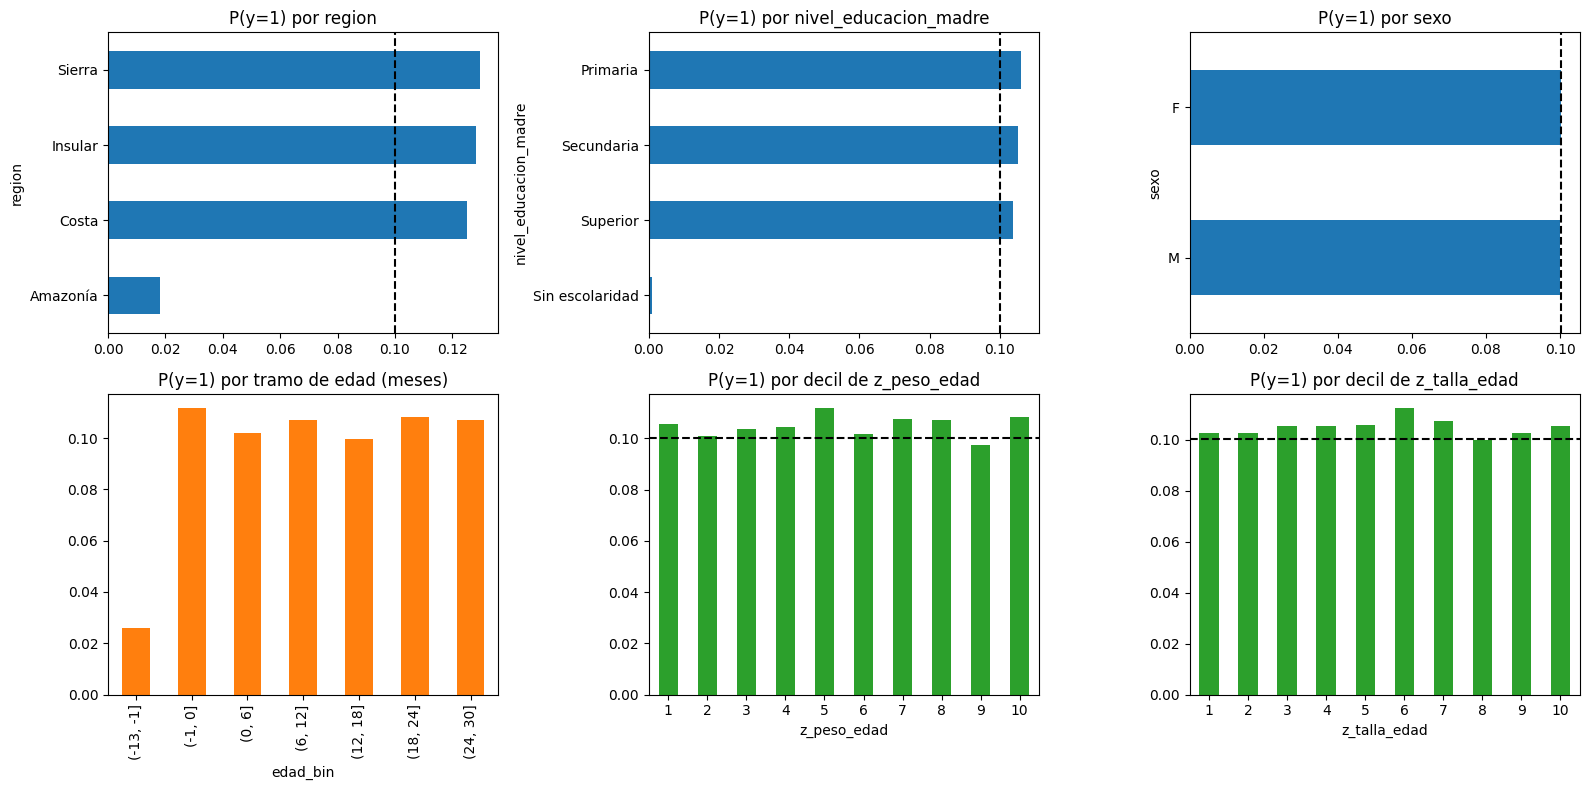

P(y=1 | peso NaN) = 0.094 | P(y=1 | talla NaN) = 0.099


nivel_educacion_madre,Primaria,Secundaria,Sin escolaridad,Superior
region,,,,
Amazonía,0.019,0.019,0.000,0.019
Costa,0.134,0.130,0.003,0.131
Insular,0.130,0.140,0.000,0.129
Sierra,0.140,0.134,0.000,0.135


In [6]:
d = X_train.assign(y=y_train)
d["edad_bin"] = pd.cut(d.edad_meses, [-13, -1, 0, 6, 12, 18, 24, 30])

# z-score empírico de peso y talla para la edad (por edad y sexo, solo valores plausibles)
v = d[d.edad_meses.between(0, 24) & d.peso_kg.between(1, 20)].copy()
g = v.groupby(["edad_meses", "sexo"])
v["z_peso_edad"]  = (v.peso_kg  - g.peso_kg.transform("median"))  / g.peso_kg.transform("std")
v["z_talla_edad"] = (v.talla_cm - g.talla_cm.transform("median")) / g.talla_cm.transform("std")

fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for a, c in zip(ax[0], ["region", "nivel_educacion_madre", "sexo"]):
    d.groupby(c).y.mean().sort_values().plot.barh(ax=a, color="tab:blue")
    a.axvline(y_train.mean(), ls="--", c="k"); a.set_title(f"P(y=1) por {c}")
d.groupby("edad_bin", observed=True).y.mean().plot.bar(ax=ax[1, 0], color="tab:orange")
ax[1, 0].set_title("P(y=1) por tramo de edad (meses)")
for a, c in zip(ax[1, 1:], ["z_peso_edad", "z_talla_edad"]):
    v.groupby(pd.qcut(v[c], 10), observed=True).y.mean().plot.bar(ax=a, color="tab:green")
    a.axhline(y_train.mean(), ls="--", c="k"); a.set_title(f"P(y=1) por decil de {c}")
    a.set_xticklabels(range(1, 11), rotation=0)
plt.tight_layout(); plt.show()

print("P(y=1 | peso NaN) =", round(d.y[d.peso_kg.isna()].mean(), 3),
      "| P(y=1 | talla NaN) =", round(d.y[d.talla_cm.isna()].mean(), 3))
display(pd.crosstab(d.region, d.nivel_educacion_madre, values=d.y, aggfunc="mean").round(3))

**Lectura esperada.** La señal es categórica: Amazonía y "Sin escolaridad" tienen prevalencias cercanas a 0, y la edad negativa reduce el riesgo. Las variables antropométricas muestran P(y=1) prácticamente plana por decil.

Ninguna celda alcanza P(y=1) > 0.5. Bajo pérdida 0-1 esto anticipa que la regla de Bayes coincide con la clase mayoritaria; las secciones 6–8 lo verifican formalmente con los modelos.

### 3.3 Validación adversarial (¿train y test provienen de la misma distribución?)

In [7]:
X_adv = pd.concat([X_train, X_test], ignore_index=True)
y_adv = np.r_[np.zeros(len(X_train)), np.ones(len(X_test))]
X_adv_enc = X_adv.copy()
for c in ["sexo", "region", "nivel_educacion_madre"]:
    X_adv_enc[c] = X_adv_enc[c].astype("category")

adv = HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=SEED)
p_adv = cross_val_predict(adv, X_adv_enc, y_adv, method="predict_proba",
                          cv=StratifiedKFold(5, shuffle=True, random_state=SEED), n_jobs=N_JOBS)[:, 1]
adv_auc = roc_auc_score(y_adv, p_adv)
print(f"AUC adversarial = {adv_auc:.4f}  (≈0.5 ⇒ sin covariate shift; la CV es representativa del test)")

AUC adversarial = 0.5024  (≈0.5 ⇒ sin covariate shift; la CV es representativa del test)


## 4. Preprocesamiento

Se implementa como transformadores de scikit-learn dentro de un `Pipeline`. Así cada fold de CV ajusta imputación y escalado solo con su parte de entrenamiento, sin fuga de información.

1. **Reglas de dominio** (`DomainCleaner`, sin parámetros aprendidos):
   - Edad fuera de [0, 24] meses → flag y recorte al rango.
   - Peso fuera de [1, 20] kg o talla fuera de [40, 100] cm → NaN y flag de outlier.
   - Flags de faltante.
2. **Numéricas:** imputación por mediana y `StandardScaler`. La estandarización es imprescindible para KNN (distancias) y MLP (condicionamiento del gradiente).
3. **Categóricas:** `OneHotEncoder`.
4. **Duplicados:** se eliminan los duplicados exactos (X, y) de train.

In [8]:
class DomainCleaner(BaseEstimator, TransformerMixin):
    # Limpieza determinista basada en rangos fisiológicos para niños de 0 a 24 meses.
    def __init__(self, edad_rng=(0, 24), peso_rng=(1.0, 20.0), talla_rng=(40.0, 100.0)):
        self.edad_rng, self.peso_rng, self.talla_rng = edad_rng, peso_rng, talla_rng

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        X["edad_neg"]   = (X.edad_meses < self.edad_rng[0]).astype(int)
        X["edad_gt24"]  = (X.edad_meses > self.edad_rng[1]).astype(int)
        X["edad_meses"] = X.edad_meses.clip(*self.edad_rng)
        X["peso_na"]    = X.peso_kg.isna().astype(int)
        X["talla_na"]   = X.talla_cm.isna().astype(int)
        X["peso_out"]   = (X.peso_kg.notna()  & ~X.peso_kg.between(*self.peso_rng)).astype(int)
        X["talla_out"]  = (X.talla_cm.notna() & ~X.talla_cm.between(*self.talla_rng)).astype(int)
        X.loc[X.peso_out == 1, "peso_kg"]   = np.nan
        X.loc[X.talla_out == 1, "talla_cm"] = np.nan
        return X

NUM = ["edad_meses", "peso_kg", "talla_cm",
       "edad_neg", "edad_gt24", "peso_na", "talla_na", "peso_out", "talla_out"]
CAT = ["sexo", "region", "nivel_educacion_madre"]

def make_pipeline(model):
    encoder = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
    ])
    return Pipeline([("clean", DomainCleaner()), ("enc", encoder), ("model", model)])

# Eliminación de duplicados exactos (X, y)
train = X_train.assign(alerta_desnutricion=y_train).drop_duplicates().reset_index(drop=True)
X, y = train[FEATURES], train["alerta_desnutricion"].values
n_dedup = len(X_train) - len(X)
print(f"Filas tras eliminar duplicados: {len(X)} (eliminadas {n_dedup})")
if SMOKE_TEST:
    idx = np.random.RandomState(SEED).choice(len(X), 4000, replace=False)
    X, y = X.iloc[idx].reset_index(drop=True), y[idx]
    print("SMOKE_TEST activo: submuestra de", len(X))

make_pipeline(DummyClassifier()).fit(X, y)["clean"].transform(X.head())

Filas tras eliminar duplicados: 69920 (eliminadas 80)


,edad_meses,sexo,region,nivel_educacion_madre,peso_kg,talla_cm,edad_neg,edad_gt24,peso_na,talla_na,peso_out,talla_out
0,0,F,Costa,Secundaria,2.243466,47.340072,0,0,0,0,0,0
1,11,M,Insular,Secundaria,6.157203,67.525274,0,0,0,0,0,0
2,22,M,Costa,Superior,9.781251,86.664662,0,0,0,0,0,0
3,4,F,Sierra,Primaria,2.972311,61.071857,0,0,0,0,0,0
4,0,F,Costa,Primaria,NaN,50.898250,1,0,1,0,0,0


## 5. Esquema de validación

- **Búsqueda de hiperparámetros:** `GridSearchCV` con `StratifiedKFold(5)` y `scoring="accuracy"`.
- **Comparación final:** `RepeatedStratifiedKFold(5×3)` con las mismas particiones para todos los modelos, lo que permite comparaciones pareadas.
- **Umbral:** fijo en 0.5. Para accuracy es el umbral de Bayes sobre probabilidades calibradas.
- **Clases:** no se usan pesos de clase ni sobremuestreo, porque desplazan el umbral efectivo y reducen la accuracy.

In [9]:
CV_SEARCH = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
CV_EVAL   = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

baseline_acc = 1 - y.mean()
print(f"Línea base (predecir siempre 0): accuracy = {baseline_acc:.4f}")

Línea base (predecir siempre 0): accuracy = 0.8998


## 6. Búsqueda de hiperparámetros

| Modelo | Motivo |
|---|---|
| Dummy (clase mayoritaria) | Referencia: regla de Bayes si P(y=1\|x) < 0.5 en todo el espacio |
| Regresión logística | Contraste lineal (no recomendado por el profesor) |
| KNN | No paramétrico, sensible a la escala y a k |
| MLP | Red neuronal para patrones no lineales, con *early stopping* |
| HistGradientBoosting | Referencia no lineal basada en árboles |

In [10]:
SEARCH_SPACE = {
    "LogReg": (LogisticRegression(max_iter=2000),
               {"model__C": [0.01, 0.1, 1.0, 10.0]}),
    "KNN": (KNeighborsClassifier(n_jobs=1),
            {"model__n_neighbors": [5, 15, 51, 101, 201, 301],
             "model__weights": ["uniform", "distance"]}),
    "MLP": (MLPClassifier(early_stopping=True, validation_fraction=0.1, n_iter_no_change=10,
                          max_iter=300, random_state=SEED),
            {"model__hidden_layer_sizes": [(64, 32), (128, 64), (256, 128, 64)],
             "model__alpha": [1e-4, 1e-3, 1e-2],
             "model__learning_rate_init": [1e-3]}),
    "HGB": (HistGradientBoostingClassifier(random_state=SEED),
            {"model__learning_rate": [0.03, 0.1],
             "model__max_leaf_nodes": [15, 31],
             "model__min_samples_leaf": [20, 100]}),
}

if SMOKE_TEST:
    SEARCH_SPACE = {k: (m, {p: v[:1] if k != "KNN" or p != "model__n_neighbors" else [5, 51]
                            for p, v in g.items()}) for k, (m, g) in SEARCH_SPACE.items()}

best_estimators = {"Dummy": make_pipeline(DummyClassifier(strategy="most_frequent"))}
search_results = {}
for name, (model, grid) in SEARCH_SPACE.items():
    t0 = time.time()
    gs = GridSearchCV(make_pipeline(model), grid, scoring="accuracy", cv=CV_SEARCH,
                      n_jobs=N_JOBS, refit=False, return_train_score=False)
    gs.fit(X, y)
    res = pd.DataFrame(gs.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
    search_results[name] = res.sort_values("rank_test_score")
    best_estimators[name] = make_pipeline(model).set_params(**gs.best_params_)
    TIMINGS[f"search_{name}"] = time.time() - t0
    print(f"{name:7s} mejor acc={gs.best_score_:.4f}  {gs.best_params_}  ({time.time() - t0:.0f}s)")

LogReg  mejor acc=0.8998  {'model__C': 0.01}  (3s)
KNN     mejor acc=0.8998  {'model__n_neighbors': 51, 'model__weights': 'uniform'}  (19s)
MLP     mejor acc=0.8998  {'model__alpha': 0.0001, 'model__hidden_layer_sizes': (64, 32), 'model__learning_rate_init': 0.001}  (22s)
HGB     mejor acc=0.8998  {'model__learning_rate': 0.03, 'model__max_leaf_nodes': 15, 'model__min_samples_leaf': 20}  (3s)


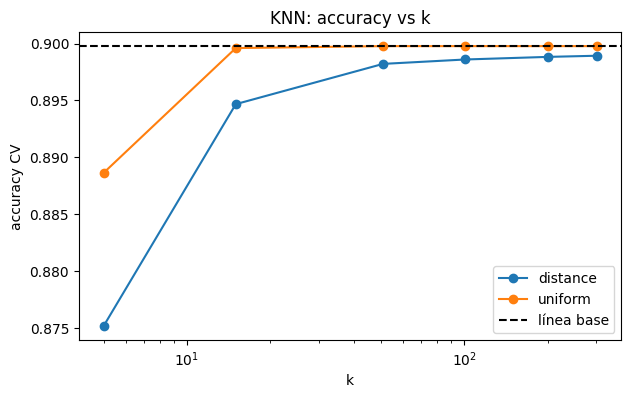

,params,mean_test_score,std_test_score,rank_test_score
0,"{'model__alpha': 0.0001, 'model__hidden_layer_...",0.899771,0.000035,1
1,"{'model__alpha': 0.0001, 'model__hidden_layer_...",0.899771,0.000035,1
2,"{'model__alpha': 0.0001, 'model__hidden_layer_...",0.899771,0.000035,1
3,"{'model__alpha': 0.001, 'model__hidden_layer_s...",0.899771,0.000035,1
4,"{'model__alpha': 0.001, 'model__hidden_layer_s...",0.899771,0.000035,1


In [11]:
# Efecto de k en KNN: k pequeño sobreajusta ruido y cae por debajo de la línea base
knn_res = search_results["KNN"].copy()
knn_res["k"] = knn_res.params.apply(lambda p: p["model__n_neighbors"])
knn_res["weights"] = knn_res.params.apply(lambda p: p["model__weights"])
ax = knn_res.pivot(index="k", columns="weights", values="mean_test_score").plot(marker="o", figsize=(7, 4))
ax.axhline(baseline_acc, ls="--", c="k", label="línea base"); ax.legend()
ax.set_xscale("log"); ax.set_ylabel("accuracy CV"); ax.set_title("KNN: accuracy vs k")
plt.show()
search_results["MLP"].head()

## 7. Evaluación final con CV repetida (5×3) y pruebas estadísticas pareadas

In [12]:
def corrected_resampled_ttest(diff, n_train, n_test):
    # Nadeau & Bengio (2003): corrige la varianza por solapamiento de los conjuntos de entrenamiento.
    J = len(diff); m = diff.mean(); s2 = diff.var(ddof=1)
    denom = np.sqrt((1 / J + n_test / n_train) * s2)
    if denom == 0:
        return 0.0, 1.0
    t = m / denom
    return t, 2 * stats.t.sf(abs(t), df=J - 1)

def mcnemar_exact(y_true, pred_a, pred_b):
    # Prueba exacta de McNemar sobre predicciones out-of-fold pareadas.
    a_ok, b_ok = pred_a == y_true, pred_b == y_true
    n01, n10 = int((a_ok & ~b_ok).sum()), int((~a_ok & b_ok).sum())
    if n01 + n10 == 0:
        return n01, n10, 1.0
    return n01, n10, stats.binomtest(n10, n01 + n10, 0.5).pvalue

fold_scores, oof_proba = {}, {}
for name, est in best_estimators.items():
    t0 = time.time()
    cvres = cross_validate(est, X, y, cv=CV_EVAL, scoring="accuracy", n_jobs=N_JOBS)
    fold_scores[name] = cvres["test_score"]
    oof_proba[name] = cross_val_predict(est, X, y, cv=CV_SEARCH, method="predict_proba", n_jobs=N_JOBS)[:, 1]
    TIMINGS[f"eval_{name}"] = time.time() - t0
    print(f"{name:7s} listo ({time.time() - t0:.0f}s)")

n_test_fold = len(y) / 5; n_train_fold = len(y) - n_test_fold
oof_dummy = (oof_proba["Dummy"] > 0.5).astype(int)
rows = []
for name in best_estimators:
    acc = fold_scores[name]; pred = (oof_proba[name] > 0.5).astype(int)
    diff = acc - fold_scores["Dummy"]
    t, p_t = corrected_resampled_ttest(diff, n_train_fold, n_test_fold)
    n01, n10, p_mc = mcnemar_exact(y, oof_dummy, pred)
    rows.append({
        "modelo": name, "acc_media": acc.mean(), "acc_std": acc.std(ddof=1),
        "Δ vs Dummy": diff.mean(), "p (t corregido)": p_t, "p (McNemar)": p_mc,
        "AUC OOF": roc_auc_score(y, oof_proba[name]) if name != "Dummy" else 0.5,
        "Brier OOF": brier_score_loss(y, oof_proba[name]),
        "% pred=1": pred.mean() * 100, "max P(y=1)": oof_proba[name].max(),
    })
summary = pd.DataFrame(rows).set_index("modelo").sort_values("acc_media", ascending=False)
summary.round(5)

Dummy   listo (1s)
LogReg  listo (1s)
KNN     listo (8s)
MLP     listo (5s)
HGB     listo (3s)


,acc_media,acc_std,Δ vs Dummy,p (t corregido),p (McNemar),AUC OOF,Brier OOF,% pred=1,max P(y=1)
modelo,,,,,,,,,
Dummy,0.89977,0.00004,0.0,1.0,1.0,0.50000,0.10023,0.0,0.00000
LogReg,0.89977,0.00004,0.0,1.0,1.0,0.65018,0.08701,0.0,0.24815
KNN,0.89977,0.00004,0.0,1.0,1.0,0.64624,0.08862,0.0,0.39216
MLP,0.89977,0.00004,0.0,1.0,1.0,0.64799,0.08731,0.0,0.24578
HGB,0.89977,0.00004,0.0,1.0,1.0,0.65010,0.08684,0.0,0.35563


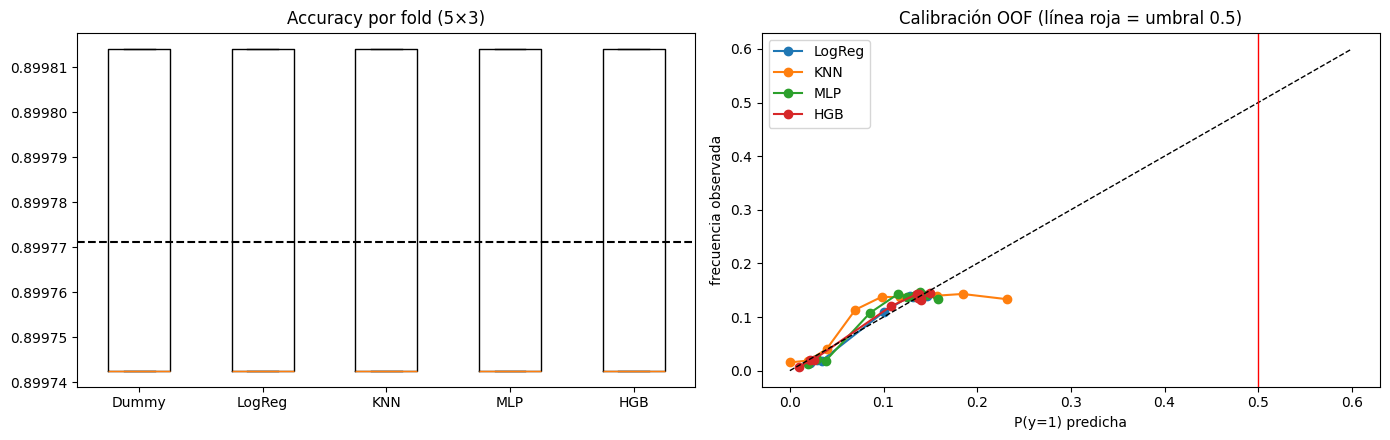

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].boxplot([fold_scores[k] for k in summary.index])
ax[0].set_xticks(range(1, len(summary) + 1)); ax[0].set_xticklabels(summary.index)
ax[0].axhline(baseline_acc, ls="--", c="k"); ax[0].set_title("Accuracy por fold (5×3)")
for name in summary.index.drop("Dummy"):
    pt, pp = calibration_curve(y, oof_proba[name], n_bins=10, strategy="quantile")
    ax[1].plot(pp, pt, marker="o", label=name)
ax[1].plot([0, 0.6], [0, 0.6], "k--", lw=1); ax[1].axvline(0.5, c="r", lw=1)
ax[1].set_xlabel("P(y=1) predicha"); ax[1].set_ylabel("frecuencia observada")
ax[1].set_title("Calibración OOF (línea roja = umbral 0.5)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 8. Regla de decisión pre-registrada

Se selecciona el modelo no trivial con mayor accuracy media en la CV 5×3. Se adopta para el envío solo si cumple las tres condiciones siguientes:

1. Su accuracy supera a la de la línea base.
2. El t-test corregido de Nadeau–Bengio da p < 0.05.
3. La prueba exacta de McNemar da p < 0.05.

Si no las cumple, ningún modelo aporta evidencia de mejora: las predicciones de 1 que emita serían ruido con pérdida esperada negativa. En ese caso se envía la regla de Bayes estimada, es decir, la clase mayoritaria. El criterio se fija antes de ver el leaderboard y es independiente de él.

In [14]:
ALPHA = 0.05
candidates = summary.drop("Dummy")
best_name = candidates.sort_values(["acc_media", "AUC OOF"], ascending=False).index[0]  # desempate por AUC
b = candidates.loc[best_name]
significant = (b["Δ vs Dummy"] > 0) and (b["p (t corregido)"] < ALPHA) and (b["p (McNemar)"] < ALPHA)

FINAL_NAME = best_name if significant else "Dummy"
print(f"Mejor modelo no trivial: {best_name}  acc={b['acc_media']:.5f}  Δ={b['Δ vs Dummy']:+.5f}  "
      f"p_t={b['p (t corregido)']:.3g}  p_McNemar={b['p (McNemar)']:.3g}")
print(f"Modelo seleccionado para el envío: {FINAL_NAME}")
print(f"Accuracy esperada en el privado (≈27 000 filas): {summary.loc[FINAL_NAME, 'acc_media']:.4f} "
      f"± {1.96 * np.sqrt(baseline_acc * (1 - baseline_acc) / 27_000):.4f} (IC 95 %)")

Mejor modelo no trivial: LogReg  acc=0.89977  Δ=+0.00000  p_t=1  p_McNemar=1
Modelo seleccionado para el envío: Dummy
Accuracy esperada en el privado (≈27 000 filas): 0.8998 ± 0.0036 (IC 95 %)


## 9. Entrenamiento final sobre todo el train y predicción de test

In [15]:
final_model = best_estimators[FINAL_NAME].fit(X, y)
test_proba = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba > 0.5).astype(int)
print(f"Predicciones test: {np.bincount(test_pred, minlength=2)}  (% de unos = {test_pred.mean() * 100:.3f})")
print(f"P(y=1) test: media={test_proba.mean():.4f}  máx={test_proba.max():.4f}")

# Referencia: qué predice en test el mejor modelo no trivial (para documentarlo, no para el envío)
if FINAL_NAME != best_name:
    ref = best_estimators[best_name].fit(X, y).predict(X_test)
    ref_proba_max = best_estimators[best_name].predict_proba(X_test)[:, 1].max()
    print(f"{best_name} predeciría {ref.sum()} unos en test; acuerdo con el envío = {(ref == test_pred).mean():.4f}")

Predicciones test: [30000     0]  (% de unos = 0.000)
P(y=1) test: media=0.0000  máx=0.0000
LogReg predeciría 0 unos en test; acuerdo con el envío = 1.0000


## 10. Construcción y validación del archivo de submission

In [16]:
submission = sample[["ID"]].copy()
submission["alerta_desnutricion"] = test_pred.astype(int)

# Validaciones de formato
assert list(submission.columns) == list(sample.columns)
assert len(submission) == len(X_test) == 30_000
assert (submission["ID"].values == sample["ID"].values).all()
assert submission["ID"].is_unique and submission["ID"].min() == 1 and submission["ID"].max() == 30_000
assert submission["alerta_desnutricion"].isin([0, 1]).all()
assert submission.isna().sum().sum() == 0
assert pd.api.types.is_integer_dtype(submission["alerta_desnutricion"])

out_path = OUT_DIR / "submission_final.csv"
submission.to_csv(out_path, index=False)

# Relectura desde disco para validar el archivo tal como se subirá
check = pd.read_csv(out_path)
assert check.shape == sample.shape and list(check.columns) == list(sample.columns)
assert check.dtypes.equals(sample.dtypes)
print(f"Archivo válido: {out_path.resolve()}")
print(check["alerta_desnutricion"].value_counts().to_dict())
check.head()

Archivo válido: D:\mcd\mcd_Fundamentos_AI\mcd_infant_malnutrition_competition\submissions\submission_final.csv
{0: 30000}


,ID,alerta_desnutricion
0,1,0
1,2,0
2,3,0
3,4,0
4,5,0


## 11. Reporte para revisión

Esta celda reúne en texto plano todo lo necesario para revisar la ejecución: entorno, calidad de datos, validación adversarial, todas las configuraciones de hiperparámetros, scores por fold, pruebas estadísticas, decisión y huella del archivo de envío.

Además lo guarda en `submissions/report_for_review.txt`.

In [17]:
import hashlib, platform, io

buf = io.StringIO()
def w(*a): print(*a, file=buf)
def sec(t): w("\n" + "=" * 100 + f"\n{t}\n" + "=" * 100)

with pd.option_context("display.max_rows", 500, "display.max_columns", 50, "display.width", 250,
                       "display.max_colwidth", 120, "display.float_format", "{:.5f}".format):
    sec("1. ENTORNO")
    w(f"Python {sys.version.split()[0]} | {platform.platform()} | CPUs={os.cpu_count()}")
    w(f"numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | scipy {__import__('scipy').__version__}")
    w(f"SMOKE_TEST={SMOKE_TEST} | SEED={SEED} | tiempo total={(time.time() - T_START) / 60:.1f} min")
    w("Tiempos (s):", {k: round(v, 1) for k, v in TIMINGS.items()})

    sec("2. DATOS")
    w(f"Train {X_train.shape} | Test {X_test.shape} | prevalencia y=1 = {y_train.mean():.5f}")
    w(f"Duplicados (X,y) eliminados = {n_dedup} | filas usadas = {len(X)} | línea base = {baseline_acc:.5f}")
    w(pd.DataFrame({"train": quality_report(X_train), "test": quality_report(X_test)}).to_string())
    w("\nP(y=1) por categoría:")
    for c in ["sexo", "region", "nivel_educacion_madre", "edad_bin"]:
        w(c, d.groupby(c, observed=True).y.agg(["mean", "size"]).round(5).to_dict("index"))
    w(f"\nAUC adversarial train vs test = {adv_auc:.5f}")

    sec("3. BÚSQUEDA DE HIPERPARÁMETROS (todas las configuraciones, CV 5-fold)")
    for name, res in search_results.items():
        w(f"\n--- {name} ---")
        w(res.to_string(index=False))

    sec("4. MEJORES CONFIGURACIONES")
    for name, est in best_estimators.items():
        w(f"{name}: {est.named_steps['model']}")

    sec("5. EVALUACIÓN CV 5x3 Y PRUEBAS ESTADÍSTICAS")
    w(summary.to_string())
    w("\nAccuracy por fold (15 folds):")
    w(pd.DataFrame(fold_scores).to_string())
    w("\nCuantiles de P(y=1) OOF por modelo:")
    w(pd.DataFrame({k: np.percentile(v, [50, 90, 99, 99.9, 100]) for k, v in oof_proba.items()},
                   index=["p50", "p90", "p99", "p99.9", "max"]).to_string())
    w("\nMatrices de confusión OOF (umbral 0.5) [[TN, FP], [FN, TP]]:")
    for k, v in oof_proba.items():
        w(f"{k}: {confusion_matrix(y, (v > 0.5).astype(int)).tolist()}")

    sec("6. DECISIÓN")
    w(f"Mejor modelo no trivial = {best_name} | significativo = {significant} | ENVÍO = {FINAL_NAME}")
    w(f"Predicciones test: ceros={int((test_pred == 0).sum())} unos={int(test_pred.sum())} | "
      f"P(y=1) test media={test_proba.mean():.5f} máx={test_proba.max():.5f}")
    if FINAL_NAME != best_name:
        w(f"{best_name} en test: unos={int(ref.sum())} | máx P(y=1)={ref_proba_max:.5f} | acuerdo con envío={(ref == test_pred).mean():.5f}")

    sec("7. ARCHIVO DE ENVÍO")
    w(f"Ruta = {out_path.resolve()}")
    w(f"Filas = {len(check)} | columnas = {list(check.columns)} | dtypes = {check.dtypes.astype(str).to_dict()}")
    w(f"Distribución = {check['alerta_desnutricion'].value_counts().to_dict()}")
    w(f"MD5 = {hashlib.md5(out_path.read_bytes()).hexdigest()}")
    w("Primeras filas:\n" + check.head(5).to_string(index=False))

report_txt = buf.getvalue()
(OUT_DIR / "report_for_review.txt").write_text(report_txt, encoding="utf-8")
print(report_txt)
print(f"\nReporte guardado en: {(OUT_DIR / 'report_for_review.txt').resolve()}")


1. ENTORNO
Python 3.11.17 | Windows-10-10.0.26200-SP0 | CPUs=16
numpy 2.3.5 | pandas 2.3.3 | scikit-learn 1.9.1 | scipy 1.16.3
SMOKE_TEST=False | SEED=42 | tiempo total=1.1 min
Tiempos (s): {'search_LogReg': 2.9, 'search_KNN': 19.0, 'search_MLP': 22.4, 'search_HGB': 3.4, 'eval_Dummy': 0.8, 'eval_LogReg': 1.1, 'eval_KNN': 7.7, 'eval_MLP': 4.8, 'eval_HGB': 2.8}

2. DATOS
Train (70000, 6) | Test (30000, 6) | prevalencia y=1 = 0.10013
Duplicados (X,y) eliminados = 80 | filas usadas = 69920 | línea base = 0.89977
                               train     test
peso_kg NaN %                4.95571  4.94333
talla_cm NaN %              10.07000  9.83667
edad < 0 %                   5.60143  5.55000
edad > 24 %                  4.51857  4.44333
peso fuera [1, 20] kg %      1.19143  1.36000
talla fuera [40, 100] cm %   0.02286  0.01333
duplicados exactos         100.00000 13.00000

P(y=1) por categoría:
sexo {'F': {'mean': 0.10036, 'size': 35185}, 'M': {'mean': 0.0999, 'size': 34815}}
region {'Am